In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_openml

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning model
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

# Save model
import joblib

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load German Credit Dataset
credit_data = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

# Separate features and target
X = credit_data.data.copy()

# Target: 1 = Bad credit, 0 = Good credit
y = (
    credit_data.target.astype(str).str.lower() == "bad"
).astype(int)

# Combine for exploration
df = X.copy()
df["Credit_Risk"] = y

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,Credit_Risk
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,1


In [3]:
# Display first five records
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,Credit_Risk
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,1



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_status,1000,4,no checking,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,existing paid,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,radio/tv,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_status,1000,5,<100,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment,1000,5,1<=X<4,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_commitment,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status,1000,4,male single,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_parties,1000,3,none,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
checking_status           0
duration                  0
credit_history            0
purpose                   0
credit_amount             0
savings_status            0
employment                0
installment_commitment    0
personal_status           0
other_parties             0
residence_since           0
property_magnitude        0
age                       0
other_payment_plans       0
housing                   0
existing_credits          0
job                       0
num_dependents            0
own_telephone             0
foreign_worker            0
Credit_Risk               0
dtype: int64

Duplicate Records:
0


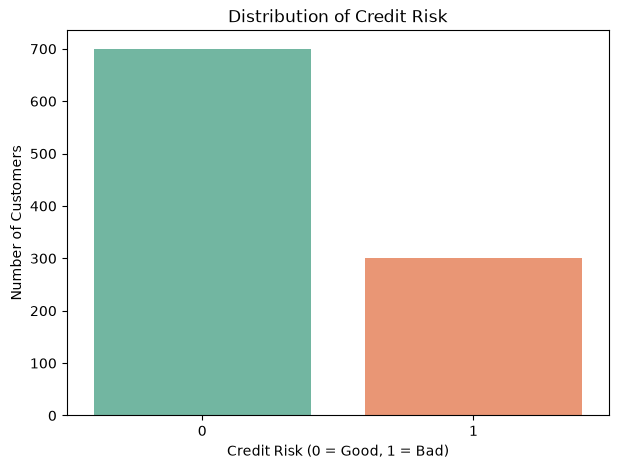

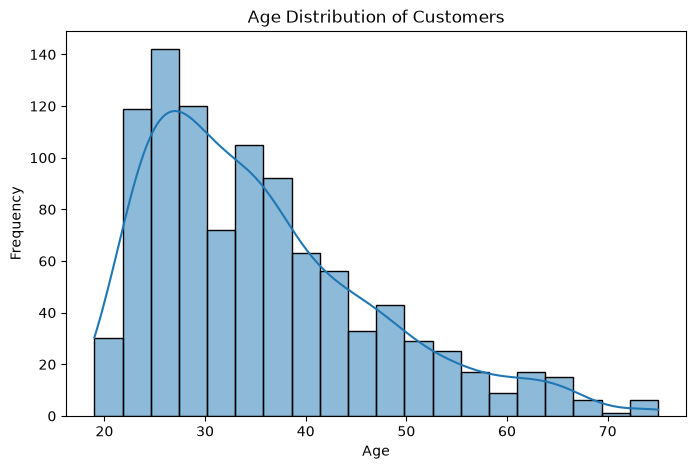

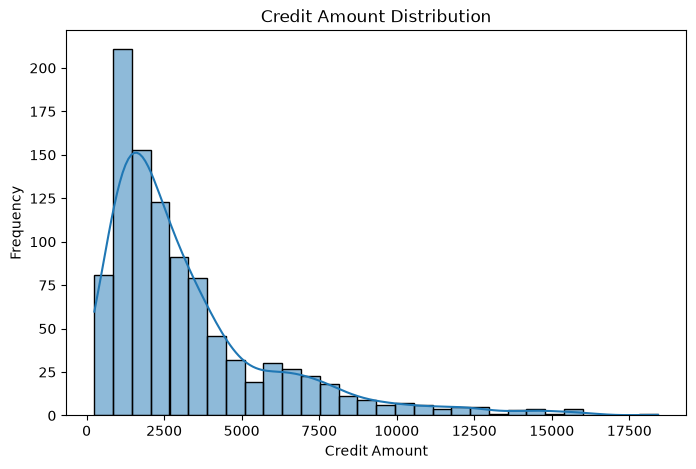

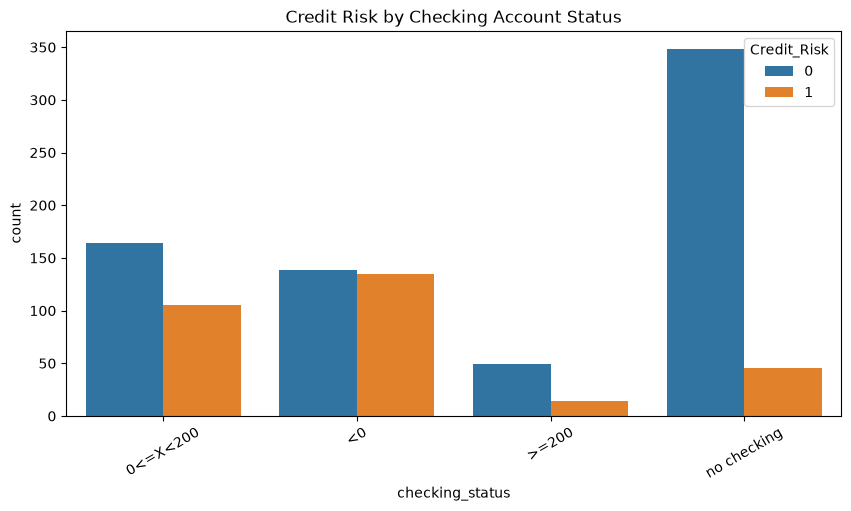

In [4]:
# Credit risk distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    x=df["Credit_Risk"],
    hue=df["Credit_Risk"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Credit Risk")
plt.xlabel("Credit Risk (0 = Good, 1 = Bad)")
plt.ylabel("Number of Customers")
plt.show()


# Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


# Credit amount distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="credit_amount",
    bins=30,
    kde=True
)

plt.title("Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Frequency")
plt.show()


# Credit risk vs checking account status
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="checking_status",
    hue="Credit_Risk"
)

plt.title("Credit Risk by Checking Account Status")
plt.xticks(rotation=30)
plt.show()

In [5]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical Features:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Categorical Features:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Preprocessing pipeline created successfully!


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Training data shape: (800, 20)
Testing data shape: (200, 20)

Training samples: 800
Testing samples: 200


In [7]:
# Create Logistic Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
model.fit(X_train, y_train)

print("Credit Scoring Model trained successfully!")

Credit Scoring Model trained successfully!


In [8]:
# Predict on test data
y_pred = model.predict(X_test)

# Prediction probabilities
y_probability = model.predict_proba(X_test)[:, 1]

# Display actual vs predicted values
results = pd.DataFrame({
    "Actual Credit Risk": y_test.values,
    "Predicted Credit Risk": y_pred
})

print("Prediction Results:")
display(results.head(15))

Prediction Results:


,Actual Credit Risk,Predicted Credit Risk
0,0,0
1,0,0
2,1,1
3,0,1
4,1,0
5,0,0
6,0,0
7,0,0
8,0,1
9,0,0


In [9]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_probability)


print("========== MODEL EVALUATION ==========")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("======================================")

========== MODEL EVALUATION ==========
Accuracy  : 75.00%
Precision : 55.81%
Recall    : 80.00%
F1 Score  : 65.75%
ROC-AUC   : 0.8058


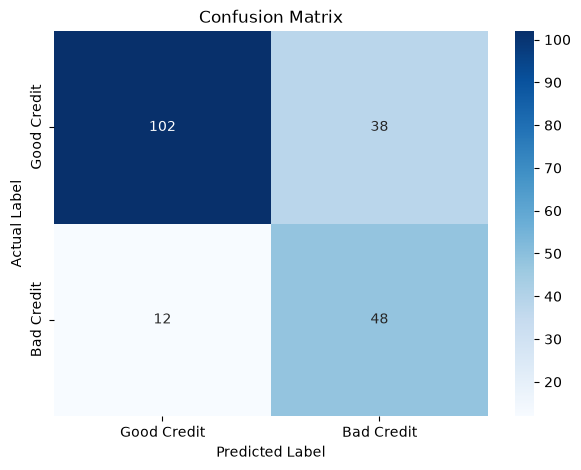

Confusion Matrix:
[[102  38]
 [ 12  48]]


In [10]:
# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Display confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Good Credit", "Bad Credit"],
    yticklabels=["Good Credit", "Bad Credit"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


print("Confusion Matrix:")
print(cm)

In [11]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Good Credit", "Bad Credit"],
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

 Good Credit       0.89      0.73      0.80       140
  Bad Credit       0.56      0.80      0.66        60

    accuracy                           0.75       200
   macro avg       0.73      0.76      0.73       200
weighted avg       0.79      0.75      0.76       200



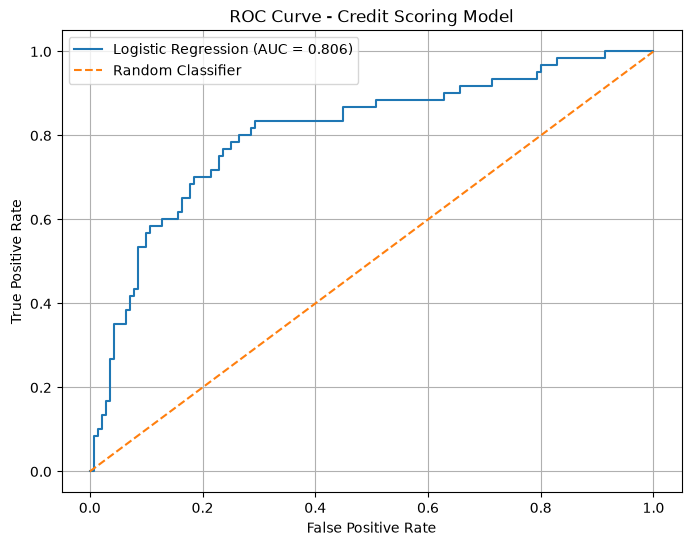

In [12]:
# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

auc_score = roc_auc_score(
    y_test,
    y_probability
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Scoring Model")

plt.legend()
plt.grid()
plt.show()

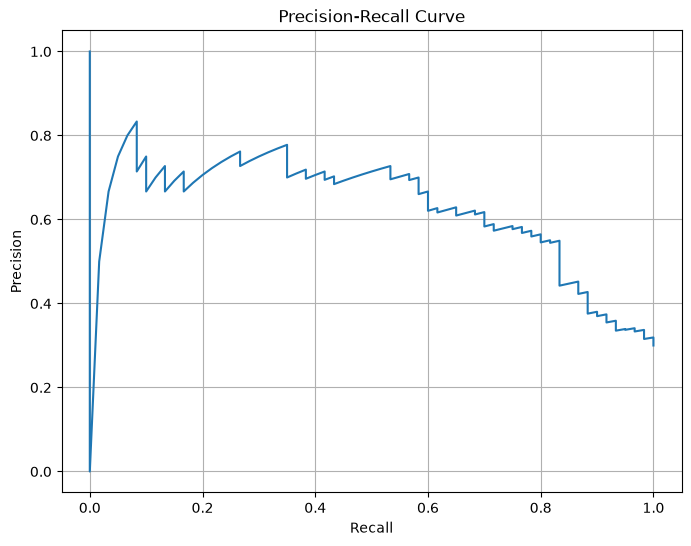

In [13]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test,
        y_probability
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid()
plt.show()

Top 15 Important Features:


,Feature,Coefficient,Absolute Importance
10,cat__checking_status_no checking,-0.987410,0.987410
18,cat__purpose_education,0.958526,0.958526
25,cat__purpose_used car,-0.887080,0.887080
12,cat__credit_history_critical/other existing cr...,-0.852003,0.852003
29,cat__savings_status_>=1000,-0.676792,0.676792
59,cat__foreign_worker_no,-0.651421,0.651421
45,cat__property_magnitude_no known property,0.635350,0.635350
8,cat__checking_status_<0,0.620797,0.620797
32,cat__employment_4<=X<7,-0.595362,0.595362
15,cat__credit_history_no credits/all paid,0.589948,0.589948


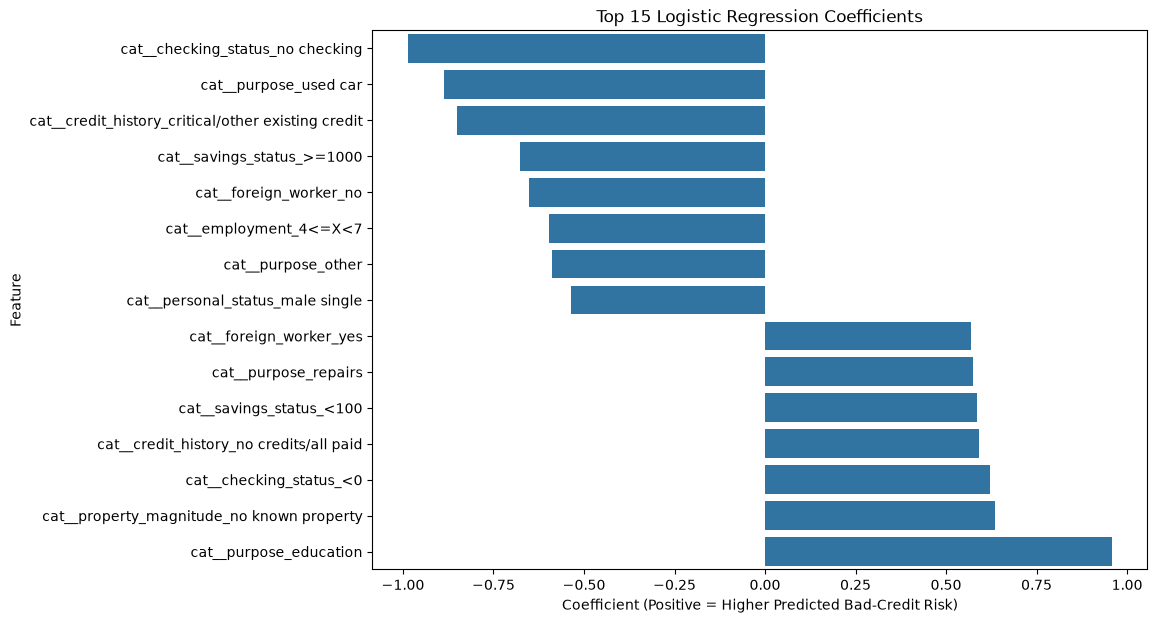

In [14]:
# Get feature names after preprocessing
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get model coefficients
coefficients = (
    model.named_steps["classifier"].coef_[0]
)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient
importance_df["Absolute Importance"] = (
    importance_df["Coefficient"].abs()
)

importance_df = importance_df.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Top 15 Important Features:")

display(importance_df.head(15))


# Plot top 15 coefficients
top_features = importance_df.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient (Positive = Higher Predicted Bad-Credit Risk)")
plt.ylabel("Feature")
plt.show()

In [15]:
# Select one sample from test data
sample = X_test.iloc[[0]]

# Predict credit risk
prediction = model.predict(sample)[0]

# Predict probability of bad credit
probability = model.predict_proba(sample)[0][1]

print("========== CUSTOMER CREDIT PREDICTION ==========")

if prediction == 1:
    print("Prediction: BAD CREDIT RISK")
else:
    print("Prediction: GOOD CREDIT RISK")

print(f"Probability of Bad Credit: {probability * 100:.2f}%")

print("\nCustomer Details:")
display(sample)

print("================================================")

========== CUSTOMER CREDIT PREDICTION ==========
Prediction: GOOD CREDIT RISK
Probability of Bad Credit: 40.66%

Customer Details:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
30,0<=X<200,18,existing paid,business,1913,>=1000,<1,3,male mar/wid,none,3,real estate,36,bank,own,1,skilled,1,yes,yes


In [16]:
# Save trained model
joblib.dump(
    model,
    "credit_scoring_model.pkl"
)

print("Model saved successfully!")

# Load saved model
loaded_model = joblib.load(
    "credit_scoring_model.pkl"
)

# Test loaded model
loaded_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Loaded Model Prediction:", loaded_prediction[0])

Model saved successfully!
Loaded Model Prediction: 0


In [17]:
from IPython.display import FileLink

FileLink('credit_scoring_model.pkl')

C:\Users\Soheli\credit_scoring_model.pkl

Conclusion:

The Credit Scoring Model was developed using Logistic Regression to classify customers into good and bad credit risk categories.

The project includes data preprocessing, exploratory data analysis, model training, and performance evaluation using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

The model demonstrates how machine learning can support credit risk assessment. However, it is an educational model and should not be used to make actual lending decisions without further validation, fairness testing, and regulatory review.